# Notebook 8: Publication Figures

This is the last notebook -- a **figure factory**. It recomputes nothing heavy: it
reads the saved outputs of Notebooks 0-9 (CSVs and summary JSONs) and renders the
figures and the theorems table the manuscript uses, as paired vector PDF (for LaTeX)
and PNG plus `.tex`, with a caption file and a manifest. An embedded self-check
confirms every figure was written and that the numbers drawn match their source.

The figures are built for a **paper**: one muted palette (slate blue + grayscale),
plain-language labels (no internal experiment or criterion codes), and almost no
text on the figure itself -- every number and definition lives in the caption. Five
figures, each earning its place, plus a theorems table:
- **F1** The weighted sum returns a single, *graded* verdict where a Hartian
  *validation rule* contradicts itself. NB the two Harts are different objects: the
  validation rule is the contradiction foil, the tiered *hierarchical Hart* is the
  determinacy baseline and does not contradict itself.
- **F2** *(central)* **Practice is not unitary** -- four models of practice ground
  the weights into three distinct structures.
- **F3** The determinacy **threshold is a modeling choice**; conclusions don't hinge
  on its value.
- **F4** The threshold drives *whether a case is decided*, but the **activation
  structure** drives the substantive requirements (global sensitivity).
- **F5** Only **cardinal** rules weigh how strongly a principle applies.
- **Theorems table** -- the five results that hold by proof, not simulation.

## Setup

On Colab this mounts your Google Drive and works in the project folder; locally it
uses the current folder. We write the shared core only for axis ordering and the
category bands (no model is run), then load every saved output and define the shared
figure style.

In [1]:
import os
PROJECT = '/content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06'
try:
    from google.colab import drive
    drive.mount('/content/drive')
    os.makedirs(PROJECT, exist_ok=True); os.chdir(PROJECT)
    print('Colab: mounted Drive, working in', os.getcwd())
except ImportError:
    print('Local: working in', os.getcwd())

Mounted at /content/drive
Colab: mounted Drive, working in /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06


In [2]:
%%writefile berman_core.py
"""
berman_core.py — shared, corrected core for the Berman Modeling rebuild (2026-06).

ONE source of truth for the SAW model, principle sets, Hart baselines, a *seeded*
bootstrap, the activation generators, the weight-tolerance (critical-sigma)
machinery, and the redesigned evaluation criteria. Every notebook %%writefile's
this file and `from berman_core import *`, so a fix here propagates everywhere
(ends the verbatim-copy drift of the old notebooks).

Design decisions baked in (vs. the old code):
  * Determinacy convention is strict |F| > tau, matching the manuscript.
  * RNG is always explicit (np.random.default_rng(seed)); bootstrap is seeded
    and vectorized, so every CI is reproducible.
  * One determinacy cutoff (DEFAULT_TAU) everywhere — no 0.05-here-0.2-there.
  * Corrected category map: federalism is STRUCTURAL, not moral.
  * Criteria are split into REQUIREMENTS (R1-R4, pass/fail, derived from what
    Berman actually claims) and DESCRIPTIVE measures (D1-D2, reported, never used
    to fail the theory). See CONCEPTUAL_AUDIT_vs_Berman.md.
"""
from __future__ import annotations

from dataclasses import dataclass
from typing import Dict, List, Optional, Callable, Tuple

import numpy as np

__all__ = [
    "DEFAULT_TAU", "Principle", "NAMED_PRINCIPLES", "CATEGORY_INDEX",
    "make_weights", "named_weight_vector", "category_of",
    "net_force", "is_determinate", "determinacy_rate",
    "random_activations", "category_correlated_activations", "fully_correlated_activations",
    "bootstrap_ci", "critical_sigma", "CRITICAL_SIGMA_CEIL",
    "hart_hierarchical_determinate", "hart_consensus_determinate", "hart_advantage",
    "hart_validation_status",
    "nonlexicality_score", "ordinalize", "saw_verdict", "lexicographic_verdict",
    "weight_cv", "n_survivors", "cluster_gap",
    "METHODOLOGIES", "methodology_tendencies", "LegalSystem",
    "gmm_bimodal", "bimodality_coefficient",
    "RelianceSystem", "weight_entropy", "gini", "n_bins_occupied",
    "set_determinism", "StrategicSystem",
    "verdict_flip_rates", "system_flip_curve", "principled_tau_percase",
    "N_P", "AppointmentEmbeddingSystem",
]

# ---------------------------------------------------------------------------
# Determinacy convention
# ---------------------------------------------------------------------------
DEFAULT_TAU: float = 0.20  # a case is determinate when |F| > tau (strict)


# ---------------------------------------------------------------------------
# Principles and categories  (federalism corrected to 'structural')
# ---------------------------------------------------------------------------
@dataclass
class Principle:
    name: str
    weight: float
    category: str = "structural"  # one of: 'textual', 'structural', 'moral'

    def __post_init__(self) -> None:
        assert 0.0 <= self.weight <= 1.0, f"weight out of [0,1]: {self.weight}"
        assert self.category in ("textual", "structural", "moral"), self.category


# The baseline 9-principle set. Order is fixed; categories are the corrected map.
NAMED_PRINCIPLES: List[Tuple[str, str]] = [
    ("text",       "textual"),
    ("original",   "textual"),
    ("precedent",  "structural"),
    ("structure",  "structural"),
    ("federalism", "structural"),   # <-- was grouped with 'moral' in the old code (bug)
    ("dignity",    "moral"),
    ("equality",   "moral"),
    ("liberty",    "moral"),
    ("welfare",    "moral"),
]

CATEGORY_INDEX: Dict[str, List[int]] = {
    cat: [i for i, (_, c) in enumerate(NAMED_PRINCIPLES) if c == cat]
    for cat in ("textual", "structural", "moral")
}


def category_of(i: int) -> str:
    return NAMED_PRINCIPLES[i][1]


# ---------------------------------------------------------------------------
# Weight generators
# ---------------------------------------------------------------------------
def make_weights(n: int, distribution: str, seed: int) -> np.ndarray:
    """Generate n weights. 'uniform' ~U(.60,.70); 'moderate' ~U(.50,.80);
    'high' ~U(.30,.95). Berman's weights are 'rough' (slight..nearly conclusive)."""
    rng = np.random.default_rng(seed)
    if distribution == "uniform":
        return rng.uniform(0.60, 0.70, n)
    if distribution == "moderate":
        return rng.uniform(0.50, 0.80, n)
    if distribution == "high":
        return rng.uniform(0.30, 0.95, n)
    raise ValueError(f"unknown distribution: {distribution}")


def named_weight_vector(distribution: str = "moderate", seed: int = 0) -> np.ndarray:
    """Weights for the 9 NAMED_PRINCIPLES under a given distribution."""
    return make_weights(len(NAMED_PRINCIPLES), distribution, seed)


# ---------------------------------------------------------------------------
# SAW model (nonlexical aggregation)
# ---------------------------------------------------------------------------
def net_force(weights: np.ndarray, activations: np.ndarray) -> np.ndarray:
    """F = sum_i w_i * a_i. Vectorized over a (..., n) activation array."""
    weights = np.asarray(weights, float)
    activations = np.asarray(activations, float)
    return np.sum(weights * activations, axis=-1)


def is_determinate(weights, activations, tau: float = DEFAULT_TAU):
    return np.abs(net_force(weights, activations)) > tau


def determinacy_rate(weights, activation_matrix, tau: float = DEFAULT_TAU) -> float:
    return float(np.mean(is_determinate(weights, activation_matrix, tau)))


# ---------------------------------------------------------------------------
# Activation generators (the conservative independent baseline + realistic structure)
# ---------------------------------------------------------------------------
def random_activations(n_cases: int, n_principles: int, rng: np.random.Generator) -> np.ndarray:
    """Independent activations ~ U(-1, 1). The conservative baseline."""
    return rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))


def category_correlated_activations(n_cases: int, rng: np.random.Generator,
                                    rho: float = 0.7) -> np.ndarray:
    """Activations for the 9 NAMED_PRINCIPLES where principles in the same
    category share a common latent factor (textual together, structural together,
    moral together)."""
    n_p = len(NAMED_PRINCIPLES)
    a = np.empty((n_cases, n_p))
    for cat, idx in CATEGORY_INDEX.items():
        factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
        idio = rng.uniform(-1.0, 1.0, size=(n_cases, len(idx)))
        a[:, idx] = np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)
    return a


def fully_correlated_activations(n_cases: int, n_principles: int,
                                 rng: np.random.Generator, rho: float = 0.7) -> np.ndarray:
    """All principles share one latent factor."""
    factor = rng.uniform(-1.0, 1.0, size=(n_cases, 1))
    idio = rng.uniform(-1.0, 1.0, size=(n_cases, n_principles))
    return np.clip(rho * factor + (1 - rho) * idio, -1.0, 1.0)


# ---------------------------------------------------------------------------
# Bootstrap — SEEDED and vectorized (every CI is reproducible)
# ---------------------------------------------------------------------------
def bootstrap_ci(values, n_boot: int = 2000, ci: int = 95, seed: int = 0):
    """Return (mean, lo, hi) for a percentile bootstrap CI on the mean."""
    rng = np.random.default_rng(seed)
    arr = np.asarray(values, dtype=float)
    if arr.size == 0:
        return (float("nan"),) * 3
    means = rng.choice(arr, size=(n_boot, arr.size), replace=True).mean(axis=1)
    lo = float(np.percentile(means, (100 - ci) / 2))
    hi = float(np.percentile(means, 100 - (100 - ci) / 2))
    return float(arr.mean()), lo, hi


# ---------------------------------------------------------------------------
# Weight-uncertainty tolerance: critical sigma  (R2 — "rough weights suffice")
# ---------------------------------------------------------------------------
CRITICAL_SIGMA_CEIL = 1.0  # grid maximum; a returned value == this is right-censored


def critical_sigma(weights: np.ndarray, activation_matrix: np.ndarray,
                   tau: float = DEFAULT_TAU, accuracy: float = 0.80,
                   robust_thresh: float = 0.90, n_mc: int = 64, seed: int = 0,
                   sigma_grid: Optional[np.ndarray] = None) -> float:
    """Smallest weight-noise sigma at which fewer than `accuracy` of cases remain
    individually robust.

    Two-level definition: add N(0, sigma^2) to each weight (clipped to [0,1]); a
    *case* is robust at sigma if it keeps its unperturbed signed VERDICT
    (determinate-for / determinate-against / indeterminate) on at least
    `robust_thresh` of MC draws; sigma* is the smallest sigma at which the
    fraction of robust cases falls below `accuracy`.

    Verdict-stability (not just determinate/indeterminate class) so that a noise
    level that flips a determinate-for case to determinate-against counts as
    instability. The grid runs to CRITICAL_SIGMA_CEIL; a returned value equal to
    the ceiling is right-censored (true tolerance is >= ceiling) -- callers
    should flag these rather than average them as if measured.
    """
    rng = np.random.default_rng(seed)
    w = np.asarray(weights, float)
    A = np.asarray(activation_matrix, float)
    n_p = w.size
    if sigma_grid is None:
        sigma_grid = np.linspace(0.0, CRITICAL_SIGMA_CEIL, 51)

    true_F = A @ w
    true_v = np.sign(true_F); true_v[np.abs(true_F) <= tau] = 0    # (cases,) verdict
    noise = rng.standard_normal((n_mc, A.shape[0], n_p))          # (mc, cases, p)

    prev_sigma, prev_surv = 0.0, 1.0
    for sigma in sigma_grid:
        if sigma == 0:
            prev_sigma, prev_surv = 0.0, 1.0
            continue
        w_noisy = np.clip(w[None, None, :] + sigma * noise, 0.0, 1.0)
        F = np.einsum("mcp,cp->mc", w_noisy, A)                   # (mc, cases)
        v = np.sign(F); v[np.abs(F) <= tau] = 0
        agree_frac = np.mean(v == true_v[None, :], axis=0)        # per case
        survival = float(np.mean(agree_frac >= robust_thresh))
        if survival < accuracy:
            frac = (accuracy - prev_surv) / (survival - prev_surv)
            return float(prev_sigma + frac * (sigma - prev_sigma))
        prev_sigma, prev_surv = sigma, survival
    return float(sigma_grid[-1])  # right-censored at the ceiling


# ---------------------------------------------------------------------------
# Hart baselines  (R4 — "more law than Hart", reported as a margin/curve)
# ---------------------------------------------------------------------------
def hart_consensus_determinate(activations, frac: float = 0.6,
                               act_cut: float = 0.1) -> np.ndarray:
    """Consensus Hart (the faithful operationalization of Hart-as-validation):
    a case is determinate only when the share of *active* principles pointing the
    same direction exceeds `frac`. Hart requires agreement; below `frac` the law
    'runs out'."""
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1)
    neg = np.sum(A < -act_cut, axis=1)
    active = pos + neg
    with np.errstate(invalid="ignore", divide="ignore"):
        share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
    return (active > 0) & (share > frac)


def hart_hierarchical_determinate(weights, activations, tier_of: np.ndarray,
                                  frac: float = 0.6, act_cut: float = 0.1,
                                  tau: float = DEFAULT_TAU) -> np.ndarray:
    """Charitable *lexical-priority* Hart: principles sit in priority tiers
    (0 = top). For each case, the highest-priority tier that has ANY active
    principle is DISPOSITIVE: that tier decides iff its active principles reach
    consensus (>= `frac` agree in sign); otherwise the law runs out. Lower tiers
    are NOT consulted once a higher tier is reached — that is the lexical priority
    Berman's nonlexical model is contrasted against, and it is what stops Hart
    from finding law in nearly every case via tier escape-hatches.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    tier_of = np.asarray(tier_of, int)
    out = np.zeros(A.shape[0], dtype=bool)
    reached = np.zeros(A.shape[0], dtype=bool)  # a dispositive tier has been reached
    for t in np.unique(tier_of):
        idx = np.where(tier_of == t)[0]
        sub = A[:, idx]
        pos = np.sum(sub > act_cut, axis=1)
        neg = np.sum(sub < -act_cut, axis=1)
        active = pos + neg
        this_tier = (active > 0) & (~reached)        # cases first resolved at this tier
        with np.errstate(invalid="ignore", divide="ignore"):
            share = np.maximum(pos, neg) / np.where(active == 0, 1, active)
        out |= this_tier & (share > frac)             # decided iff consensus here (strict, matches consensus Hart)
        reached |= this_tier                           # dispositive; no escape downward
    return out


def hart_validation_status(activations, k: int = 2, act_cut: float = 0.5) -> np.ndarray:
    """Naive validation foil used to make Berman's 'no contradiction' point.

    A direction counts as independently 'validated' when at least `k` principles
    are strongly activated (|a| > act_cut) in that direction. Returns one integer
    code per case:
        0 = gap          (neither direction validated -> the law runs out)
        1 = for          (only the positive direction validated)
        2 = against      (only the negative direction validated)
        3 = contradiction(both directions validated -> q and not-q are both law)

    The point: code 3 is possible for a validation model, but impossible for
    Berman's aggregation, because a single net force has a single sign. So the sum
    never returns code 3.
    """
    A = np.atleast_2d(np.asarray(activations, float))
    pos = np.sum(A > act_cut, axis=1) >= k
    neg = np.sum(A < -act_cut, axis=1) >= k
    code = np.zeros(A.shape[0], dtype=int)
    code[pos & ~neg] = 1
    code[neg & ~pos] = 2
    code[pos & neg] = 3
    return code


def hart_advantage(weights, activation_matrix, tier_of, frac: float = 0.6,
                   tau: float = DEFAULT_TAU) -> float:
    """Berman determinacy rate minus hierarchical-Hart determinacy rate (a margin,
    not a pass/fail)."""
    berman = determinacy_rate(weights, activation_matrix, tau)
    hart = float(np.mean(hart_hierarchical_determinate(
        weights, activation_matrix, tier_of, frac=frac, tau=tau)))
    return berman - hart


# ---------------------------------------------------------------------------
# R3 — nonlexicality.  Does determination track activation MAGNITUDES (and many
# principles jointly), as Berman requires, rather than just signs/ranks (lexical)?
# ---------------------------------------------------------------------------
def ordinalize(weights: np.ndarray) -> np.ndarray:
    """Replace weights by rank-based pseudo-weights (1..n)/n — discards cardinal info."""
    order = np.argsort(np.argsort(weights))  # ranks 0..n-1
    return (order + 1) / len(weights)


# Verdict functions return an integer verdict per case: +1 / -1 (determinate for
# / against) or 0 (indeterminate). These are the inputs to the R3 nonlexicality
# probe and are reused by the aggregation-function suite.
def saw_verdict(weights, activation_matrix, tau: float = DEFAULT_TAU) -> np.ndarray:
    """Nonlexical: verdict from the *magnitude-weighted sum* of all principles."""
    F = np.asarray(activation_matrix, float) @ np.asarray(weights, float)
    v = np.sign(F)
    v[np.abs(F) <= tau] = 0
    return v.astype(int)


def lexicographic_verdict(weights, activation_matrix, act_cut: float = 0.05) -> np.ndarray:
    """Lexical: verdict from the SIGN of the single highest-weight active
    principle (Raz exclusionary-reasons style). This is the mode Berman's theory
    is defined against — included only as the lexical foil for the R3 probe."""
    w = np.asarray(weights, float)
    A = np.atleast_2d(np.asarray(activation_matrix, float))
    order = np.argsort(-w)  # highest weight first
    out = np.zeros(A.shape[0], dtype=int)
    decided = np.zeros(A.shape[0], dtype=bool)
    for j in order:
        active = (np.abs(A[:, j]) > act_cut) & (~decided)
        out[active] = np.sign(A[active, j]).astype(int)
        decided |= active
    return out


def nonlexicality_score(verdict_fn: Callable[[np.ndarray], np.ndarray],
                        activation_matrix: np.ndarray,
                        seed: int = 0, n_mc: int = 32, jitter: float = 0.20) -> float:
    """R3 probe. Fraction of cases whose VERDICT changes under a magnitude-only
    perturbation of activations that preserves every activation's sign AND the
    within-case rank order of |activation|.

    A lexical rule (decides on the top-ranked active principle) is invariant to
    such perturbations -> score ~ 0. A genuinely nonlexical, magnitude-aggregating
    rule (SAW) is sensitive -> score > 0. `verdict_fn(A)` maps an (n,9) activation
    matrix to an integer verdict array in {-1,0,+1}.
    """
    rng = np.random.default_rng(seed)
    A = np.asarray(activation_matrix, float)
    base = verdict_fn(A)
    rank = np.argsort(np.argsort(np.abs(A), axis=1), axis=1)  # rank of |a| within row
    n_p = A.shape[1]
    changed = np.zeros(A.shape[0])
    for _ in range(n_mc):
        mag = np.clip(np.abs(A) * (1 + rng.uniform(-jitter, jitter, A.shape)), 0, 1)
        sorted_mag = np.sort(mag, axis=1)
        # Strictly-increasing epsilon breaks ties created when two magnitudes both
        # clip to 1.0; without this, re-placing tied values by index can silently
        # change the rank order (and thus the decision of a lexical rule). This
        # guarantees |A2| keeps the ORIGINAL within-row rank order exactly.
        sorted_mag = sorted_mag + 1e-9 * np.arange(n_p)
        A2 = np.sign(A) * np.take_along_axis(sorted_mag, rank, axis=1)
        changed += (verdict_fn(A2) != base)
    return float(np.mean(changed / n_mc))


# ---------------------------------------------------------------------------
# Descriptive weight statistics (D1 gradation, and emergence diagnostics)
# ---------------------------------------------------------------------------
def weight_cv(weights: np.ndarray) -> float:
    w = np.asarray(weights, float)
    m = w.mean()
    return float(w.std() / m) if m > 0 else 0.0


def n_survivors(weights: np.ndarray, cutoff: float = 0.05) -> int:
    return int(np.sum(np.asarray(weights, float) > cutoff))


def cluster_gap(weights: np.ndarray) -> float:
    """Gap between the two k-means clusters of weights (bimodality diagnostic)."""
    w = np.sort(np.asarray(weights, float))
    if w.size < 2:
        return 0.0
    best = None
    for k in range(1, w.size):
        lo, hi = w[:k], w[k:]
        gap = hi.mean() - lo.mean()
        if best is None or gap > best:
            best = gap
    return float(best)


# ===========================================================================
# Agent-based model of weight emergence (Notebook 1)
# ===========================================================================
# A bench of judges, each carrying an interpretive methodology that sets how
# often it invokes each principle. A principle's emergent "uptake share" is how
# often the bench takes it up across decisions. This is a deliberately simple
# model of Berman's "taking-up" (JESP p. 302); it is NOT his full account of
# weight, which is conferred by reliance and by winning conflicts (pp. 322, 324)
# and is taken up in Notebook 1c. The emergent quantity here is called "uptake
# share," never "weight in Berman's sense."

METHODOLOGIES = ("textualist", "purposivist", "pragmatist", "originalist")

# For each methodology, the principles it tends to invoke often ('high') or
# rarely ('low'); anything unlisted is 'medium'. Names refer to NAMED_PRINCIPLES.
_METH_SETS = {
    "textualist":  {"high": {"text", "original"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
    "purposivist": {"high": {"dignity", "equality", "liberty"},
                    "low":  {"text", "original", "federalism"}},
    "pragmatist":  {"high": {"welfare", "precedent"},
                    "low":  {"dignity", "equality", "original"}},
    "originalist": {"high": {"original", "text", "federalism"},
                    "low":  {"dignity", "equality", "liberty", "welfare"}},
}

# Invocation-probability ranges (high, medium, low) by how specialized the
# methodologies are. 'wide' = strong specialization (headline); 'narrow' = nearly
# homogeneous (used to show heterogeneity is necessary for the split).
_SPREAD_RANGES = {
    "wide":   ((0.85, 0.95), (0.35, 0.65), (0.02, 0.08)),
    "medium": ((0.70, 0.80), (0.40, 0.60), (0.15, 0.25)),
    "narrow": ((0.60, 0.70), (0.42, 0.58), (0.30, 0.40)),
}


def methodology_tendencies(methodology: str, spread: str, rng) -> np.ndarray:
    """A 9-vector of per-principle invocation probabilities for one judge of a
    given methodology, drawn from the high/medium/low ranges set by `spread`."""
    hi, med, lo = _SPREAD_RANGES[spread]
    sets = _METH_SETS[methodology]
    t = np.empty(len(NAMED_PRINCIPLES))
    for i, (name, _) in enumerate(NAMED_PRINCIPLES):
        rng_range = hi if name in sets["high"] else (lo if name in sets["low"] else med)
        t[i] = rng.uniform(*rng_range)
    return t


class LegalSystem:
    """A bench of judges whose case-by-case invocations produce emergent
    principle uptake-shares.

    `turnover` selects how judges are replaced over time:
      'static'      no replacement (the headline emergence must hold here);
      'fitness'     replace the least decisive 20% with mutated copies of the
                    most decisive 20% (the old, suspect, non-Bermanian rule);
      'appointment' replace a random 20%, reseated from the methodology pool;
      'noise'       replace a random 20% with mutated copies of random judges.
    The point of the four regimes is to show the emergent structure does NOT
    depend on the turnover rule.
    """

    def __init__(self, n_agents=100, methodology_mix=None, spread="wide",
                 use_threshold=True, threshold_pct=50, turnover="static",
                 boost_cut=0.3, learn_from_system=0.15, seed=0):
        # One master seed -> five independent streams. No global np.random.
        ss = np.random.SeedSequence(seed)
        (self._rng_agents, self._rng_panels, self._rng_cases,
         self._rng_dec, self._rng_rep) = (np.random.default_rng(s) for s in ss.spawn(5))
        self.n_agents = n_agents
        self.spread = spread
        self.use_threshold = use_threshold
        self.threshold_pct = threshold_pct
        self.turnover = turnover
        self.boost_cut = boost_cut
        self.learn_from_system = learn_from_system
        self.n_p = len(NAMED_PRINCIPLES)

        # Assign methodologies exactly (round-robin or a given mix), then permute
        # the arrangement with the seeded generator (never np.random.shuffle).
        if methodology_mix is None:
            base = [METHODOLOGIES[i % 4] for i in range(n_agents)]
        else:
            base = []
            for m, frac in methodology_mix.items():
                base += [m] * int(round(frac * n_agents))
            base = (base + [METHODOLOGIES[0]] * n_agents)[:n_agents]
        self.methodology = list(self._rng_agents.permutation(base))
        self.tendencies = np.array([methodology_tendencies(m, spread, self._rng_agents)
                                    for m in self.methodology])     # (n_agents, 9)
        self.system_weights = np.full(self.n_p, 0.5)                # uniform init
        self.raw_uptake = np.full(self.n_p, 0.5)                    # pre-threshold share
        self.success = np.zeros(n_agents)
        self.decisions = np.zeros(n_agents)
        self.trajectory = []

    def _recompute_weights(self, counts, total):
        raw = counts / max(total, 1)
        raw = raw / max(raw.max(), 1e-12)                           # normalize to max
        self.raw_uptake = raw.copy()                               # the pre-threshold vector
        w = raw.copy()
        if self.use_threshold:                                     # zero the bottom percentile
            cut = np.percentile(w, self.threshold_pct)
            w = np.where(w < cut, 0.0, w)
            if w.max() > 0:
                w = w / w.max()
        self.system_weights = w

    def _replace(self, idx_out, idx_template):
        for o, t in zip(idx_out, idx_template):
            self.methodology[o] = self.methodology[t]
            self.tendencies[o] = np.clip(self.tendencies[t] + self._rng_rep.normal(0, 0.03, self.n_p),
                                         0.02, 0.98)
            self.success[o] = 0.0
            self.decisions[o] = 0.0

    def _turnover_step(self):
        k = max(1, int(0.2 * self.n_agents))
        if self.turnover == "static":
            return
        if self.turnover == "fitness":
            # eligible only with >= 5 decisions, so 1-2-case luck cannot rank an agent
            rate = np.where(self.decisions >= 5, self.success / np.maximum(self.decisions, 1), -1.0)
            order = np.argsort(rate)
            self._replace(order[:k], order[-k:])                   # bottom k <- top k
        elif self.turnover == "appointment":
            for o in self._rng_rep.choice(self.n_agents, k, replace=False):
                m = METHODOLOGIES[int(self._rng_rep.integers(4))]
                self.methodology[o] = m
                self.tendencies[o] = methodology_tendencies(m, self.spread, self._rng_rep)
                self.success[o] = 0.0
                self.decisions[o] = 0.0
        elif self.turnover == "noise":
            self._replace(self._rng_rep.choice(self.n_agents, k, replace=False),
                          self._rng_rep.choice(self.n_agents, k, replace=False))

    def simulate(self, n_cases=2000, panel_size=9, update_every=100, selection_every=500):
        counts = np.zeros(self.n_p)
        total = 0
        A = self._rng_cases.uniform(-1, 1, size=(n_cases, self.n_p))           # case stream up front
        panels = np.array([self._rng_panels.choice(self.n_agents, panel_size, replace=False)
                           for _ in range(n_cases)])
        self.trajectory = []
        for c in range(n_cases):
            a = A[c]
            panel = panels[c]
            tend = self.tendencies[panel]                                      # (panel, 9)
            prob = 0.85 * tend + self.learn_from_system * self.system_weights[None, :]
            boost = np.abs(a) > self.boost_cut                                 # strong activations invoked more
            prob = np.where(boost[None, :], np.minimum(prob * 1.15, 0.99), prob)
            invoked = self._rng_dec.uniform(size=(panel_size, self.n_p)) < prob
            counts += invoked.sum(axis=0)
            total += int(invoked.sum())
            forces = (invoked * self.system_weights[None, :] * a[None, :]).sum(axis=1)  # SAW per judge
            med = np.median(np.abs(forces))
            self.success[panel] += (np.abs(forces) >= med)                     # fitness bookkeeping
            self.decisions[panel] += 1
            if (c + 1) % update_every == 0:
                self._recompute_weights(counts, total)
                # record the smooth pre-threshold uptake for convergence/trajectory
                self.trajectory.append((c + 1, self.raw_uptake.copy()))
            if (c + 1) % selection_every == 0:
                self._turnover_step()
        self._recompute_weights(counts, total)
        return self.system_weights


def gmm_bimodal(values, seed=0, dbic_thresh=10.0):
    """Two-vs-one Gaussian-mixture BIC test for bimodality. Returns
    (dbic, separated, is_bimodal): dbic = BIC(1) - BIC(2) (larger favors two
    components); `separated` requires the two means be at least one larger-
    component SD apart (rejects two overlapping Gaussians). Deterministic."""
    from sklearn.mixture import GaussianMixture
    x = np.asarray(values, float).reshape(-1, 1)
    if len(np.unique(np.round(x, 6))) < 2:
        return 0.0, False, False
    g1 = GaussianMixture(1, random_state=seed, n_init=5).fit(x)
    g2 = GaussianMixture(2, random_state=seed, n_init=5).fit(x)
    dbic = float(g1.bic(x) - g2.bic(x))
    means = g2.means_.ravel()
    sds = np.sqrt(g2.covariances_.ravel())
    separated = bool(abs(means[0] - means[1]) > sds.max())
    return dbic, separated, bool(dbic > dbic_thresh and separated)


def bimodality_coefficient(values):
    """Sarle's bimodality coefficient. > 0.555 suggests bimodality. Underpowered
    for very small n, so use it on pooled data, not a single 9-vector."""
    from scipy import stats as _st
    x = np.asarray(values, float)
    n = x.size
    if n < 4:
        return float("nan")
    g = _st.skew(x); k = _st.kurtosis(x, fisher=True)
    return float((g**2 + 1) / (k + 3 * (n - 1)**2 / ((n - 2) * (n - 3))))


# ===========================================================================
# Reliance / by-battle weight conferral (Notebook 2)
# ===========================================================================
# Berman's conferred weight (JESP pp. 322, 324): a principle gains weight by
# winning CONTESTED, DISPOSITIVE battles, amplified by how much the deciding
# precedent is later RELIED UPON (cited), decayed gradually, and removed when a
# precedent is OVERRULED. Battles are decided by a FIXED exogenous "pressure"
# structure (the practice), NOT by the conferred weight being built: making it
# literally circular ("weight made so by battle") produces runaway lock-in, so
# the decision and the read-out are decoupled. There is NO weight floor -- that
# is what made the old "precedent stock" collapse to uniform weights.

def weight_entropy(w):
    """Shannon entropy of a normalized weight vector (higher = more spread)."""
    w = np.asarray(w, float); s = w.sum()
    if s <= 0:
        return 0.0
    p = w / s; p = p[p > 0]
    return float(-(p * np.log(p)).sum())


def gini(w):
    """Gini coefficient of a weight vector (0 = equal, ->1 = concentrated)."""
    w = np.sort(np.asarray(w, float)); n = len(w)
    if w.sum() == 0:
        return 0.0
    return float((2 * np.arange(1, n + 1) - n - 1).dot(w) / (n * w.sum()))


def n_bins_occupied(w, edges=(0.2, 0.4, 0.6, 0.8)):
    """How many of Berman's ~5 rough weight bands a weight vector occupies."""
    return int(len(np.unique(np.digitize(np.asarray(w, float), edges))))


class RelianceSystem:
    """Conferred weight as reliance-amplified, decayed, overruling-prunable
    battle-victories. Battles are decided by `pressure_weights` (fixed), and the
    conferred weight is read out separately, so the dynamics cannot lock in."""

    def __init__(self, pressure_weights=None, invoke_prob=None, salience=None,
                 activations="correlated", cite_mode="similarity", n_cite=3,
                 overrule_rate=0.02, decay_rate=0.9995, clash_cut=0.10,
                 feedback_alpha=0.0, tau=DEFAULT_TAU, seed=0):
        # feedback_alpha > 0 feeds the running conferred weight back into the
        # battle decision (the literally-circular "made so by battle"). It exists
        # only to DEMONSTRATE the runaway lock-in that justifies the decoupled
        # design; the headline runs use feedback_alpha = 0.
        ss = np.random.SeedSequence(seed)
        (self._rng_cases, self._rng_cite, self._rng_over,
         self._rng_inv, self._rng_setup) = (np.random.default_rng(s) for s in ss.spawn(5))
        n_p = len(NAMED_PRINCIPLES)
        self.n_p = n_p
        self.pressure_weights = (named_weight_vector("high", seed) if pressure_weights is None
                                 else np.asarray(pressure_weights, float))
        # uptake invocation propensity. It tracks the same exogenous PRESSURE
        # structure that decides battles (a principle pressed harder is invoked
        # more and can win more), so uptake and conferred weight are correlated
        # but distinct. It is NOT a function of the conferred weight being built,
        # so the two can still come apart (the forced-loser demo overrides it).
        self.invoke_prob = (np.clip(0.2 + 0.7 * (self.pressure_weights / self.pressure_weights.max())
                                    + self._rng_setup.normal(0, 0.05, n_p), 0.05, 0.98)
                            if invoke_prob is None else np.asarray(invoke_prob, float))
        self.salience = np.ones(n_p) if salience is None else np.asarray(salience, float)
        self.activations, self.cite_mode, self.n_cite = activations, cite_mode, n_cite
        self.overrule_rate, self.decay_rate, self.clash_cut, self.tau = \
            overrule_rate, decay_rate, clash_cut, tau
        self.feedback_alpha = feedback_alpha
        self.invoked_total = np.zeros(n_p)
        self.n_seen = 0
        self._ns = 0

    def run(self, n_cases=2000):
        np_ = self.n_p
        A = (category_correlated_activations(n_cases, self._rng_cases) if self.activations == "correlated"
             else random_activations(n_cases, np_, self._rng_cases))
        A = np.clip(A * self.salience[None, :], -1, 1)
        inv = self._rng_inv.uniform(size=(n_cases, np_))
        act = np.zeros((n_cases, np_)); winners = np.zeros((n_cases, np_), bool)
        verdict = np.zeros(n_cases); margin = np.zeros(n_cases); opposing = np.zeros(n_cases)
        contested = np.zeros(n_cases, bool); cc = np.zeros(n_cases)
        good = np.zeros(n_cases, bool); born = np.zeros(n_cases, int); nrm = np.zeros(n_cases)
        ns = 0
        eff = self.pressure_weights.copy()                        # effective decision pressure
        for c in range(n_cases):
            a = A[c]
            self.invoked_total += (inv[c] < self.invoke_prob)     # uptake (weight-independent)
            self.n_seen += 1
            contrib = eff * a
            F = contrib.sum()
            if abs(F) <= self.tau:
                continue                                          # equipoise: no victor
            v = 1.0 if F > 0 else -1.0
            big = np.abs(contrib) > self.clash_cut
            win = (np.sign(contrib) == v) & big                  # dispositive winners only
            cont = bool((contrib > self.clash_cut).any() and (contrib < -self.clash_cut).any())
            opp = float(np.abs(contrib[(np.sign(contrib) != v) & big]).sum())
            act[ns] = a; winners[ns] = win; verdict[ns] = v; margin[ns] = abs(F)
            opposing[ns] = opp; contested[ns] = cont; born[ns] = c
            nrm[ns] = np.linalg.norm(a); good[ns] = True
            if ns > 0:                                           # reliance: cite prior good precedents
                gi = np.where(good[:ns])[0]
                if len(gi):
                    if self.cite_mode == "preferential":
                        order = gi[np.argsort(-cc[gi])]
                    elif self.cite_mode == "random":
                        order = self._rng_cite.permutation(gi)
                    else:                                        # similarity / blended (cosine of facts)
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        score = sims * (1 + cc[gi]) if self.cite_mode == "blended" else sims
                        order = gi[np.argsort(-score)]
                    cc[order[:self.n_cite]] += 1
                    if self._rng_over.uniform() < self.overrule_rate:   # overrule a contradictory good precedent
                        sims = (act[gi] @ a) / (nrm[gi] * np.linalg.norm(a) + 1e-9)
                        cand = gi[(verdict[gi] == -v) & (sims > 0.5)]
                        if len(cand):
                            good[cand[0]] = False
            ns += 1
            if self.feedback_alpha > 0 and (c + 1) % 100 == 0 and ns > 0:
                mm = good[:ns] & contested[:ns]                   # lock-in demo: feed weight back into decisions
                if mm.any():
                    dec = self.decay_rate ** ((c + 1) - born[:ns][mm])
                    eq = opposing[:ns][mm] / (margin[:ns][mm] + opposing[:ns][mm] + 1e-9)
                    amp = margin[:ns][mm] * (1 + cc[:ns][mm]) * eq * dec
                    cur = (amp[:, None] * winners[:ns][mm]).sum(axis=0)
                    if cur.max() > 0:
                        eff = (1 - self.feedback_alpha) * self.pressure_weights + \
                              self.feedback_alpha * (cur / cur.max())
        self._act, self._winners, self._verdict = act[:ns], winners[:ns], verdict[:ns]
        self._margin, self._opposing, self._contested = margin[:ns], opposing[:ns], contested[:ns]
        self._cc, self._good, self._born = cc[:ns], good[:ns], born[:ns]
        self._n_cases, self._ns = n_cases, ns
        return self.read_weights()

    def _readout(self, use_reliance=True, use_equipoise=True):
        if self._ns == 0:
            return np.zeros(self.n_p)
        m = self._good & self._contested
        if not m.any():
            return np.zeros(self.n_p)
        decay = self.decay_rate ** (self._n_cases - self._born[m])
        equ = (self._opposing[m] / (self._margin[m] + self._opposing[m] + 1e-9)) if use_equipoise else 1.0
        rel = (1 + self._cc[m]) if use_reliance else 1.0
        amp = self._margin[m] * rel * equ * decay
        conf = (amp[:, None] * self._winners[m]).sum(axis=0)
        mx = conf.max()
        return conf / mx if mx > 0 else conf

    def read_weights(self):
        return self._readout(True, True)

    def read_weights_no_reliance(self):
        return self._readout(False, True)

    @property
    def uptake_share(self):
        return self.invoked_total / max(self.n_seen, 1)


# ---------------------------------------------------------------------------
# Threshold robustness (NB4): how stable is a verdict under perturbation, and
# what threshold tau would a verdict-robustness criterion recommend?
#
# The criterion is SIGN-robustness: a verdict is robust if its DIRECTION survives
# realistic noise. A threshold tau "protects" determinate verdicts by discarding
# exactly the sign-fragile (near-equipoise) cases -- so robustness rises with tau,
# which means robustness pins a confidence LEVEL, not a unique tau value.
# ---------------------------------------------------------------------------
def verdict_flip_rates(w, A, tau, sigma_w, n_mc=200, seed=0):
    """Per-case flip rate of the gated verdict (sign of F, with |F|<=tau set to 0)
    under weight perturbation w + N(0, sigma_w^2). Returns (v0, |F0|, flip_rate)."""
    w = np.asarray(w, float); A = np.asarray(A, float); n_p = len(w)
    rng = np.random.default_rng(seed)
    F0 = A @ w
    v0 = np.sign(F0); v0[np.abs(F0) <= tau] = 0.0
    wn = np.clip(w[None, None, :] + sigma_w * rng.standard_normal((n_mc, 1, n_p)), 0.0, 1.0)
    F = np.einsum("mcp,cp->mc", np.broadcast_to(wn, (n_mc, A.shape[0], n_p)), A)
    v = np.sign(F); v[np.abs(F) <= tau] = 0.0
    flip = np.mean(v != v0[None, :], axis=0)
    return v0, np.abs(F0), flip


def principled_tau_percase(w, A, sigma_w=0.10, P=0.90, q=0.10, n_mc=200, seed=0):
    """Per-case sustained-crossing read-off. Using SIGN-robustness (does the
    verdict direction survive the noise?), find the smallest |F| cut at and above
    which the (smoothed) robust fraction stays >= P. Returns (tau*, centers, smooth)."""
    _, absF, flip_sign = verdict_flip_rates(w, A, tau=0.0, sigma_w=sigma_w, n_mc=n_mc, seed=seed)
    robust = (flip_sign <= q).astype(float)
    order = np.argsort(absF)
    absF_s, robust_s = absF[order], robust[order]
    window = max(25, len(absF) // 40)
    smooth = np.convolve(robust_s, np.ones(window) / window, mode="valid")
    centers = absF_s[window // 2: window // 2 + len(smooth)]
    ok = smooth >= P
    sustained = ok & np.cumprod(ok[::-1])[::-1].astype(bool)    # >= P from here up
    idx = int(np.argmax(sustained)) if sustained.any() else None
    return (float(centers[idx]) if idx is not None else float("nan")), centers, smooth


def system_flip_curve(w, A, tau_grid, sigma_w=0.10, P=0.90, q=0.10, n_mc=200, seed=0):
    """System sign-robust fraction over a tau grid. For each tau, among cases the
    model calls determinate (|F0|>tau), the fraction whose SIGN is robust (sign-flip
    rate <= q) under weight noise. tau* = smallest tau where it reaches and stays >=P.
    Returns (tau_grid, robust_fraction, n_determinate, tau*)."""
    w = np.asarray(w, float); A = np.asarray(A, float); n_p = len(w)
    F0 = A @ w; absF0 = np.abs(F0)
    rng = np.random.default_rng(seed)
    wn = np.clip(w[None, None, :] + sigma_w * rng.standard_normal((n_mc, 1, n_p)), 0.0, 1.0)
    F = np.einsum("mcp,cp->mc", np.broadcast_to(wn, (n_mc, A.shape[0], n_p)), A)
    v_sign = np.sign(F)
    robust_frac = np.full(len(tau_grid), np.nan); n_det = np.zeros(len(tau_grid))
    for i, tau in enumerate(tau_grid):
        v0 = np.sign(F0); v0[absF0 <= tau] = 0.0
        det = v0 != 0; n_det[i] = det.sum()
        if det.sum() == 0:
            continue
        flip = np.mean(v_sign[:, det] != v0[None, det], axis=0)
        robust_frac[i] = float(np.mean(flip <= q))
    valid = ~np.isnan(robust_frac); okv = (robust_frac >= P) & valid
    sustained = np.zeros(len(tau_grid), bool); run = True
    for j in range(len(tau_grid) - 1, -1, -1):
        if not valid[j]:
            continue
        run = run and okv[j]; sustained[j] = run
    idx = int(np.argmax(sustained)) if sustained.any() else None
    return tau_grid, robust_frac, n_det, (float(tau_grid[idx]) if idx is not None else float("nan"))


# ---------------------------------------------------------------------------
# Mechanism 3: STRATEGIC LEARNING (multi-agent reinforcement learning)
#
# The third candidate model of "the practice that confers the weights." Judges
# are reward-optimising agents: each has a context-sensitive INVOCATION policy
# (a small shared net plus a per-judge methodology lean) and the bench shares one
# context-free WEIGHT head. The learned weight multiplies activations inside each
# judge's SAW force, so optimisation moves a genuine SAW weight -- not an
# invocation count (the bug in the original paper's MARL).
#
# This is the LEAST Bermanian of the three mechanisms: Berman never describes
# judges optimising a goal. It is a robustness probe, not an interpretation of
# Berman. Reliance (RelianceSystem) is the closest to his account; uptake
# (LegalSystem) is a simplification; this is a third lens.
# ---------------------------------------------------------------------------
def set_determinism(seed: int):
    """Make a torch run reproducible and return a seeded generator to thread
    through every random draw (so sampling never touches the global stream)."""
    import torch
    torch.manual_seed(seed)
    np.random.seed(seed)
    try:
        torch.use_deterministic_algorithms(True)
    except Exception:
        pass
    torch.set_num_threads(1)                 # 1 thread => deterministic + fast enough (tiny net)
    g = torch.Generator()
    g.manual_seed(seed)
    return g


class StrategicSystem:
    """Judges as reward-optimising RL agents; the learned WEIGHT head is read out
    as the emergent SAW weight vector.

    Key design points (see module header):
      * The weight enters the force the reward optimises:
            F_i = sum_p invoked_{i,p} * w_p * a_p,   w = sigmoid(weight_logit).
      * The per-principle contribution is a *stochastic* Normal node, so the
        REINFORCE log-prob carries gradient into the weight head. Without this the
        weight only sits in a detached scalar reward and never moves (stays frozen).
      * Reward = consensus agreement routed through the SAW force, with
        decisiveness GATED ON AGREEMENT, minus a parsimony penalty -- which kills
        the degenerate "invoke everything" optimum.
      * Learning rate anneals linearly to 0 (anneal=True), which gives a stable,
        reproducible read-out at the end of training. NOTE: the flat tail is partly
        a consequence of the annealing schedule, not by itself proof that a unique
        fixed point was reached -- the weight is read from the settled region the
        optimiser occupies. Set anneal=False to hold the rate and inspect the
        un-frozen process (the scalar weight keeps wandering; the structural
        *pattern* is stable -- the notebook demonstrates this).

    The readout is the continuous learned weight (normalised to max=1), NOT a
    thresholded invocation frequency (which would merely reproduce LegalSystem
    uptake). It plugs straight into net_force / saw_verdict / critical_sigma.
    Because the weight gradient is gated by invocation, the learned structure stays
    correlated with how often principles are invoked -- the readout is a different
    *quantity* from uptake, not an uncorrelated one.
    """

    def __init__(self, n_agents=24, panel_size=9, n_episodes=6000, lr_inv=5e-3,
                 sigma=0.08, parsimony=0.08, decisive_bonus=0.5, activations="correlated",
                 neutral_init=False, null_reward=False, anneal=True, tau=DEFAULT_TAU,
                 checkpoint=200, seed=0):
        import torch
        import torch.nn as nn
        assert panel_size % 2 == 1, "panel_size must be odd so the majority sign is never a tie"
        self.g = set_determinism(seed)
        n_p = len(NAMED_PRINCIPLES)
        self.n_p, self.n_agents, self.panel_size = n_p, n_agents, panel_size
        self.n_episodes, self.lr_inv, self.checkpoint = n_episodes, lr_inv, checkpoint
        self.sigma, self.parsimony, self.decisive_bonus = sigma, parsimony, decisive_bonus
        self.activations, self.tau, self.seed = activations, tau, seed
        self.null_reward = null_reward      # ablation: replace the reward with a constant (no signal)
        self.anneal = anneal                # anneal LR to 0 (stable read-out) vs hold it (inspect the process)
        # numpy streams for cases and panels (the NB1/NB2 SeedSequence pattern)
        ss = np.random.SeedSequence(seed)
        self._rng_cases, self._rng_panels = (np.random.default_rng(s) for s in ss.spawn(2))
        # invocation policy: one shared body + a per-judge bias (methodology lean)
        self.net = nn.Sequential(nn.Linear(n_p, 32), nn.ReLU(), nn.Linear(32, n_p))
        bias = np.zeros((n_agents, n_p))
        if not neutral_init:                                   # shared start with LegalSystem/RelianceSystem
            for i in range(n_agents):
                t = methodology_tendencies(METHODOLOGIES[i % 4], "wide",
                                           np.random.default_rng(seed * 1000 + i))
                t = np.clip(t, 1e-3, 1 - 1e-3)
                bias[i] = np.log(t / (1 - t))                  # tendencies -> logit space
        self.bias = nn.Parameter(torch.tensor(bias, dtype=torch.float32))
        wl = torch.empty(n_p)
        nn.init.normal_(wl, 0.0, 0.30)                         # weight head not degenerate-uniform at init
        self.weight_logit = nn.Parameter(wl)
        self.init_weight = torch.sigmoid(wl).detach().numpy().copy()
        self.weight_history = []   # readout() every `checkpoint` episodes (convergence)
        self.reward_history = []   # EMA reward at each checkpoint (training curve)
        self.delta_history = []    # mean|W(t)-W(t-1)| between checkpoints
        self._trained = False

    def readout(self):
        """The emergent SAW weight: continuous learned weight normalised to max=1."""
        import torch
        w = torch.sigmoid(self.weight_logit).detach().numpy()
        m = w.max()
        return w / m if m > 0 else w

    def train(self):
        import math
        import torch
        opt = torch.optim.Adam([
            {"params": list(self.net.parameters()) + [self.bias], "lr": self.lr_inv},
            {"params": [self.weight_logit], "lr": 4 * self.lr_inv},   # weaker Gaussian gradient -> higher LR
        ])
        init_lrs = [self.lr_inv, 4 * self.lr_inv]
        logconst = math.log(self.sigma * math.sqrt(2 * math.pi))
        baseline = 0.0
        A = (category_correlated_activations(self.n_episodes, self._rng_cases)
             if self.activations == "correlated"
             else random_activations(self.n_episodes, self.n_p, self._rng_cases))
        panels = np.array([self._rng_panels.choice(self.n_agents, self.panel_size, replace=False)
                           for _ in range(self.n_episodes)])
        for ep in range(self.n_episodes):
            frac = (1.0 - ep / self.n_episodes) if self.anneal else 1.0   # anneal to 0, or hold the rate
            for grp, il in zip(opt.param_groups, init_lrs):
                grp["lr"] = il * frac
            a = torch.tensor(A[ep], dtype=torch.float32)
            logits = self.net(a)[None, :] + self.bias[panels[ep]]      # (P, n_p): context + per-judge lean
            p = torch.sigmoid(logits)
            invoked = torch.bernoulli(p, generator=self.g)
            log_prob_inv = (invoked * torch.log(p + 1e-8)
                            + (1 - invoked) * torch.log(1 - p + 1e-8)).sum(1)
            w = torch.sigmoid(self.weight_logit)
            mean_c = invoked * w[None, :] * a[None, :]                 # SAW contribution; carries w-gradient
            eps = torch.randn(mean_c.shape, generator=self.g)
            c = (mean_c + self.sigma * eps).detach()                  # sampled action (detached)
            log_prob_w = (-0.5 * ((c - mean_c) / self.sigma) ** 2 - logconst).sum(1)
            F = c.sum(1)                                               # judge force = genuine weighted SAW sum
            maj = torch.sign(torch.sign(F).sum())                     # panel-majority verdict sign
            agreed = (torch.sign(F) == maj).float()
            decisive = (F.abs() > self.tau).float()
            if self.null_reward:
                reward = torch.ones(self.panel_size)          # ablation: no learning signal -> weight goes uniform
            else:
                reward = (agreed + self.decisive_bonus * decisive * agreed
                          - self.parsimony * (invoked.sum(1) / self.n_p))
            adv = (reward - baseline).detach()                        # baseline = variance-reducing EMA
            baseline = 0.99 * baseline + 0.01 * float(reward.mean())
            loss = -((log_prob_inv + log_prob_w) * adv).mean() + 1e-3 * (self.weight_logit ** 2).sum()
            opt.zero_grad()
            loss.backward()
            opt.step()
            if (ep + 1) % self.checkpoint == 0:
                r = self.readout()
                if self.weight_history:
                    self.delta_history.append(float(np.abs(r - self.weight_history[-1]).mean()))
                self.weight_history.append(r)
                self.reward_history.append(float(baseline))
        self._trained = True
        return self.readout()

    def converged(self, window=5, tol=0.01):
        """True if the readout has plateaued: mean of the last `window`
        between-checkpoint deltas is below `tol`."""
        if len(self.delta_history) < window:
            return False
        return float(np.mean(self.delta_history[-window:])) < tol

    @property
    def delta_last(self):
        return self.delta_history[-1] if self.delta_history else float("nan")

    def moved_from_init(self):
        """Mean absolute change of the (normalised) weight from its init -- a check
        that the weight head actually trained rather than staying frozen."""
        init_norm = self.init_weight / max(self.init_weight.max(), 1e-9)
        return float(np.abs(self.readout() - init_norm).mean())



# ---------------------------------------------------------------------------
# Mechanism 4: APPOINTMENT + EMBEDDING dynamics (the dynamics of changing grounds)
# Exogenous appointment shocks (no fitness) + a ledger of holdings whose still-live
# breadth sustains principle vitality; disavowal is a fast exit. Answers Berman's
# third-dynamic + embedding-via-holdings + disavowal points.
# ---------------------------------------------------------------------------
N_P = len(NAMED_PRINCIPLES)


class AppointmentEmbeddingSystem:
    """Practice dynamics = appointment shocks (changing decision-pressure) + an
    embedding LEDGER of holdings that sustain principle vitality, with disavowal as
    a fast exit. The emergent weight is read from STILL-LIVE holding-support.

    Decision pressure (which side wins a battle) comes from the SITTING BENCH, a
    pool of judges each with a personal pressure vector. Appointment replaces a
    random cohort with newcomers drawn from a methodology pool (NOT fitness-ranked).
    This is the exogenous, social-acceptance dynamic Berman asked for.

    A decided, CONTESTED battle deposits a HOLDING that credits the principles on
    its dispositive winning side. A holding stays live (and keeps crediting) until
    it is OVERRULED (slow, case-by-case) or one of its support principles is
    DISAVOWED (fast, wholesale). Holding-support_i = sum over live holdings that
    credit i of (decayed) holding strength. Vitality of i = its live holding-
    support, which does NOT require i to be currently invoked.

    Two read-out channels are kept SEPARATE (anti-double-count):
      * holding_support  : mass of live holdings resting on each principle (HEADLINE)
      * reliance_credit  : the RelianceSystem-style citation-amplified battle credit
    """

    def __init__(self, pressure_weights=None, activations="correlated",
                 n_judges=25, cohort_frac=0.20, appoint_every=200,
                 overrule_rate=0.02, decay_rate=0.9995, clash_cut=0.05,
                 n_cite=3, strength_mix=0.0, tau=DEFAULT_TAU, cap=4200, seed=0):
        ss = np.random.SeedSequence(seed)
        (self._rng_cases, self._rng_cite, self._rng_over,
         self._rng_app, self._rng_setup) = (np.random.default_rng(s) for s in ss.spawn(5))
        self.activations = activations
        self.n_judges = n_judges
        self.cohort_frac = cohort_frac
        self.appoint_every = appoint_every
        self.overrule_rate = overrule_rate
        self.decay_rate = decay_rate
        self.clash_cut = clash_cut
        self.n_cite = n_cite
        self.strength_mix = strength_mix     # how much a holding's |F| margin smooths its unit breadth
        self.tau = tau
        self.cap = cap

        # exogenous "true" pressure structure of the legal culture. Newcomer judges
        # are drawn around it (social acceptance: most newcomers resemble the
        # prevailing culture, with idiosyncratic spread), NOT selected for fitness.
        self.base_pressure = (named_weight_vector("high", seed) if pressure_weights is None
                              else np.asarray(pressure_weights, float))
        self.judges = self._draw_cohort(self.n_judges)            # (n_judges, n_p)

        # invocation propensity tracks the SITTING bench's current mean pressure;
        # recomputed after each appointment so "current invocation" and "holding
        # support" are different channels that can come apart.
        self._refresh_invoke_prob()

        # ----- holding ledger (the embedding stock; extends RelianceSystem) -----
        self.h_n = 0
        self.h_credit = np.zeros((cap, N_P), bool)   # which principles a holding rests on
        self.h_strength = np.zeros(cap)              # |F| margin at deposit (holding weight)
        self.h_born = np.zeros(cap, int)
        self.h_live = np.zeros(cap, bool)            # killed by overrule OR disavowal
        self.h_act = np.zeros((cap, N_P))            # facts (for overruling similarity)
        self.h_norm = np.ones(cap)
        self.h_verdict = np.zeros(cap, int)
        self.h_cc = np.zeros(cap)                    # citations (RELIANCE channel; separate)

        # bookkeeping
        self.invoked_total = np.zeros(N_P)
        self.n_seen = 0
        self.invoked_window = np.zeros(N_P)          # invocations since last exit event
        self.n_seen_window = 0
        self.disavowed = np.zeros(N_P, bool)
        self.invoke_lock0 = np.zeros(N_P, bool)      # principles forced to zero invocation (desuetude demo)
        self._n_cases = 0
        self._global_c = 0       # persistent case counter across run() calls -- the true decay clock

    # ---- judges / appointment -------------------------------------------------
    def _draw_cohort(self, k):
        """k newcomer judges, each a personal pressure vector around base_pressure.
        Social-acceptance spread, NOT fitness selection."""
        base = self.base_pressure / max(self.base_pressure.max(), 1e-9)
        out = np.clip(base[None, :] + self._rng_app.normal(0, 0.20, (k, N_P)), 0.02, 1.0)
        return out

    def _refresh_invoke_prob(self):
        eff = self.judges.mean(axis=0)
        self.eff_pressure = eff
        ip = np.clip(0.2 + 0.7 * (eff / max(eff.max(), 1e-9))
                     + self._rng_setup.normal(0, 0.05, N_P), 0.05, 0.98)
        self.invoke_prob = ip

    def appoint(self):
        """Replace a random cohort of sitting judges with newcomers (exogenous
        appointment shock; random, NOT fitness-ranked)."""
        k = max(1, int(round(self.cohort_frac * self.n_judges)))
        out = self._rng_app.choice(self.n_judges, k, replace=False)
        self.judges[out] = self._draw_cohort(k)
        self._refresh_invoke_prob()

    # ---- disavowal (fast exit) ------------------------------------------------
    def disavow(self, principle_idx):
        """Active denunciation of a principle: (i) zero its current invocation
        pressure going forward, AND (ii) invalidate every live holding that rests on
        it. Fast, wholesale exit -- contrast with desuetude (stop invoking; let
        holding-support decay slowly)."""
        self.disavowed[principle_idx] = True
        self.invoke_prob[principle_idx] = 0.0
        self.invoked_window[:] = 0.0; self.n_seen_window = 0   # start a fresh post-exit window
        if self.h_n > 0:
            kill = self.h_live[:self.h_n] & self.h_credit[:self.h_n, principle_idx]
            self.h_live[:self.h_n][kill] = False

    def force_desuetude(self, principle_idx):
        """Stop INVOKING a principle entirely (current uptake -> ~0) but DO NOT
        touch its holdings. The demo that vitality != invocation: holding-support
        keeps the principle alive while its underpinning holdings stand."""
        self.invoke_lock0[principle_idx] = True
        self.invoke_prob[principle_idx] = 0.0
        self.invoked_window[:] = 0.0; self.n_seen_window = 0   # start a fresh post-exit window

    # ---- main loop ------------------------------------------------------------
    def run(self, n_cases=2000):
        self._n_cases = n_cases
        A = (category_correlated_activations(n_cases, self._rng_cases)
             if self.activations == "correlated"
             else random_activations(n_cases, N_P, self._rng_cases))
        inv = self._rng_cite.uniform(size=(n_cases, N_P))
        for c in range(n_cases):
            a = A[c]
            self._global_c += 1                        # advance the persistent decay clock
            # current invocation (uptake channel). A principle must be INVOKED this
            # case to be eligible to underpin a new holding -- so desuetude (no
            # invocation) genuinely stops a principle gaining new holdings, while
            # holding-support of EXISTING holdings persists (vitality != invocation,
            # but new-holding accrual DOES need invocation -- the non-degenerate link).
            ip = self.invoke_prob.copy()
            ip[self.invoke_lock0] = 0.0
            invoked = inv[c] < ip
            self.invoked_total += invoked
            self.invoked_window += invoked   # reset by force_desuetude / disavow
            self.n_seen += 1
            self.n_seen_window += 1

            # battle decided by the SITTING bench's effective pressure
            contrib = self.eff_pressure * a
            F = contrib.sum()
            if abs(F) <= self.tau:
                pass  # equipoise: no victor, no holding deposited
            else:
                v = 1 if F > 0 else -1
                big = np.abs(contrib) > self.clash_cut
                # a holding rests on the principles that were on the DISPOSITIVE
                # winning side AND were actually INVOKED in the case (and not disavowed)
                win = (np.sign(contrib) == v) & big & invoked & (~self.disavowed)
                contested = bool((contrib > self.clash_cut).any()
                                 and (contrib < -self.clash_cut).any())
                # reliance channel: cite + maybe overrule prior live holdings
                self._cite_and_overrule(a, v)
                if contested and win.any() and self.h_n < self.cap:
                    i = self.h_n
                    self.h_credit[i] = win
                    self.h_strength[i] = abs(F)
                    self.h_born[i] = self._global_c
                    self.h_live[i] = True
                    self.h_act[i] = a
                    self.h_norm[i] = np.linalg.norm(a) + 1e-12
                    self.h_verdict[i] = v
                    self.h_n += 1

            if (c + 1) % self.appoint_every == 0:
                self.appoint()
        return self.read_weights()

    def _cite_and_overrule(self, a, v):
        n = self.h_n
        if n == 0:
            return
        live = self.h_live[:n]
        if not live.any():
            return
        sim = (self.h_act[:n] @ a) / (self.h_norm[:n] * (np.linalg.norm(a) + 1e-12))
        # reliance: cite the most similar live holdings (RELIANCE channel only)
        score = np.where(live, sim, -np.inf)
        k = min(self.n_cite, int(live.sum()))
        if k > 0:
            top = np.argpartition(-score, k - 1)[:k]
            self.h_cc[top] += 1.0
        # overruling: a contradictory, similar live holding may be pruned (slow)
        if self._rng_over.uniform() < self.overrule_rate:
            cand = np.where(live & (self.h_verdict[:n] == -v) & (sim > 0.5))[0]
            if len(cand):
                self.h_live[cand[0]] = False

    # ---- read-outs (TWO SEPARATE channels; anti-double-count) -----------------
    def holding_support(self, normalize=True, as_clock=None):
        """HEADLINE weight: BREADTH of STILL-LIVE holdings resting on each
        principle, lightly time-decayed. This is a COUNT-LIKE functional (how many
        accepted holdings underpin the principle, decayed), deliberately DIFFERENT
        from the reliance channel's citation-amplified margin (a concentration
        functional). Vitality of a principle = the accepted holdings that rest on
        it, NOT its current invocation, and NOT how heavily a few are cited.

        `as_clock` overrides the decay reference time (default = self._n_cases, i.e.
        'now'); the desuetude demo passes a later clock so post-exit decay shows.
        """
        n = self.h_n
        if n == 0:
            return np.zeros(N_P)
        live = self.h_live[:n]
        if not live.any():
            return np.zeros(N_P)
        clock = self._global_c if as_clock is None else as_clock
        decay = self.decay_rate ** np.maximum(clock - self.h_born[:n][live], 0)
        # breadth, lightly smoothed by how DECISIVE each holding was. Each live
        # holding contributes (1 + strength_mix * |F|)*decay to every principle it
        # rests on. strength_mix=0 => pure breadth (count of live holdings);
        # strength_mix small keeps it breadth-DOMINATED but lets a strongly-decided
        # holding count for a bit more. (strength_mix is a near-inert knob: it does
        # NOT move the rough-weight tolerance R2, which stays ~0.87 regardless -- the
        # flat breadth vector is simply the least noise-robust of the mechanisms.)
        # It stays a DIFFERENT functional from reliance (which multiplies by
        # (1+citations)^2, a concentration on heavily-relied-on precedents).
        wt = (1.0 + self.strength_mix * self.h_strength[:n][live]) * decay
        support = (self.h_credit[:n][live] * wt[:, None]).sum(axis=0)
        if normalize and support.max() > 0:
            support = support / support.max()
        return support

    def reliance_credit(self, normalize=True):
        """RELIANCE channel (the RelianceSystem-style read): live-holding battle
        credit AMPLIFIED by citations AND weighted by the |F| margin (a CONCENTRATION
        functional -- a few heavily-relied-on strong precedents dominate). Kept
        SEPARATE from holding_support so the two are never summed into one inflated
        number (anti-double-count), and built on a DIFFERENT functional so they are
        not the same number twice."""
        n = self.h_n
        if n == 0:
            return np.zeros(N_P)
        live = self.h_live[:n]
        if not live.any():
            return np.zeros(N_P)
        decay = self.decay_rate ** np.maximum(self._global_c - self.h_born[:n][live], 0)
        amp = self.h_strength[:n][live] * (1.0 + self.h_cc[:n][live]) ** 2 * decay
        credit = (self.h_credit[:n][live] * amp[:, None]).sum(axis=0)
        if normalize and credit.max() > 0:
            credit = credit / credit.max()
        return credit

    def live_share(self):
        """Per-principle SHARE of total live-holding breadth (sums to ~1 over
        principles, ignoring multi-credit). The desuetude read: a principle that
        stops winning NEW holdings loses share SLOWLY -- mostly because the live
        corpus keeps GROWING around it (dilution of the denominator), with time-decay
        and the occasional overrule of its own holdings as minor contributors. The
        contrast with disavowal's instant zeroing is the point."""
        s = self.holding_support(normalize=False)
        tot = s.sum()
        return s / tot if tot > 0 else s

    def read_weights(self):
        return self.holding_support(normalize=True)

    @property
    def uptake_share(self):
        return self.invoked_total / max(self.n_seen, 1)

    @property
    def uptake_window(self):
        """Invocation share over only the cases SINCE the last exit event -- the
        honest 'current invocation' read for the desuetude demo (the cumulative
        uptake_share is dominated by the pre-desuetude history)."""
        return self.invoked_window / max(self.n_seen_window, 1)

    def live_holdings(self):
        return int(self.h_live[:self.h_n].sum())



if __name__ == "__main__":
    # quick self-test: static properties
    rng = np.random.default_rng(0)
    w = named_weight_vector("moderate", seed=0)
    A = random_activations(2000, 9, rng)
    print("categories:", CATEGORY_INDEX)
    print("determinacy rate (tau=0.2):", round(determinacy_rate(w, A), 4))
    print("critical sigma:", round(critical_sigma(w, A), 4))
    print("nonlexicality SAW vs lexical:",
          round(nonlexicality_score(lambda X: saw_verdict(w, X), A), 4),
          round(nonlexicality_score(lambda X: lexicographic_verdict(w, X), A), 4))
    # quick self-test: ABM emergence
    sysm = LegalSystem(turnover="static", seed=0)
    we = sysm.simulate(n_cases=2000)
    print("\nABM emergent uptake (post-threshold):", np.round(we, 2))
    print("ABM raw uptake (pre-threshold):", np.round(sysm.raw_uptake, 2))
    print("emerged (!= uniform):", not np.allclose(sysm.raw_uptake, 0.5))
    print("raw-uptake bimodal (GMM):", gmm_bimodal(sysm.raw_uptake))
    print("cluster gap:", round(cluster_gap(sysm.raw_uptake), 3), "| CV:", round(weight_cv(sysm.raw_uptake), 3))


Overwriting berman_core.py


In [3]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.patches as mpatches
from berman_core import NAMED_PRINCIPLES, CATEGORY_INDEX, DEFAULT_TAU
PUB = 'figures/pub'; os.makedirs(PUB, exist_ok=True)
PN  = [p for p,_ in NAMED_PRINCIPLES]
PRETTY = {'text':'text','original':'original meaning','precedent':'precedent','structure':'structure',
          'federalism':'federalism','dignity':'dignity','equality':'equality','liberty':'liberty','welfare':'welfare'}
BANDS = [('textual',CATEGORY_INDEX['textual']),('structural',CATEGORY_INDEX['structural']),('moral',CATEGORY_INDEX['moral'])]
# ---- one muted palette: slate blue accent + grayscale ----
SLATE='#5b7aa6'; NAVY='#2f4b6e'; STEEL='#aebfd4'           # blue family (multi-series)
GREY='#8a8a8a'; GREYD='#5f5f5f'; GREYL='#c2c2c2'; INK='#33373d'
MECHC = {'stipulated':GREY,'uptake':SLATE,'reliance':NAVY,'strategic':STEEL}
SOFTMAP = LinearSegmentedColormap.from_list('soft', ['#f5f6f8','#aebfd4','#39527a'])
plt.rcParams.update({'font.size':9.5,'axes.titlesize':10,'axes.titleweight':'normal',
                     'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110,'font.family':'DejaVu Sans'})
def savefig(fig, n, slug):
    base = f'{PUB}/F{n}_{slug}'
    fig.savefig(base+'.pdf', bbox_inches='tight'); fig.savefig(base+'.png', dpi=600, bbox_inches='tight')
    plt.show(); return os.path.basename(base)+'.pdf'
def L(path): return json.load(open(path))
# ---- load every saved output (no recompute) ----
S0=L('data/notebook0/notebook0_summary.json'); S1=L('data/notebook1/notebook1_summary.json'); S7=L('data/notebook7_results.json')
TAU=pd.read_csv('data/notebook4/tau_grid.csv')
SOB=pd.read_csv('data/notebook6/sobol_determinacy.csv'); PANEL=pd.read_csv('data/notebook6/sobol_panel_S1.csv', index_col=0)
NLX=pd.read_csv('data/notebook5/nb5_nonlexicality.csv')
W4=pd.read_csv('data/notebook9/exp_fourway_weights.csv', index_col=0)
M4=pd.read_csv('data/notebook9/exp_fourway_metrics.csv', index_col=0)
C4=pd.read_csv('data/notebook9/exp_fourway_corr.csv'); CD={r['pair']:r['spearman'] for _,r in C4.iterrows()}
MANIFEST={}; SRCVALS={}
print('loaded all outputs; figures ->', os.path.abspath(PUB))

loaded all outputs; figures -> /content/drive/MyDrive/DGK Lab/Reasoning Lab/DGK Lab - Berman Modeling/Experiment/Run_2026-06/figures/pub


## F1 -- A single, graded verdict where a validation rule contradicts itself

The faithful core. On the same conflicting cases a Hartian *validation rule* --
which asks only whether each authority is valid and which way it points, and so
certifies both camps at once -- contradicts itself every time, while the weighted
sum returns one verdict -- mostly determinate,
with some honest indeterminacy, and never a contradiction. The right panel shows the
model on the paper's worked examples, including the genuine split-the-bench case
(TVA / Powell).

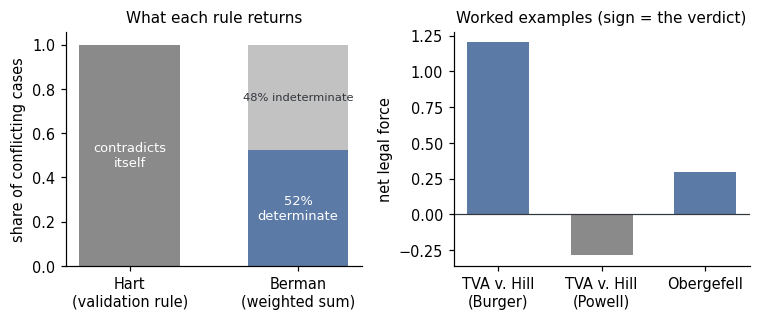

In [4]:
hart=S0['exp3b']['hart']; berm=S0['exp3b']['berman']; wk=S0['worked']
fig,ax=plt.subplots(1,2,figsize=(7.0,3.0))
cats=['Hart\n(validation rule)','Berman\n(weighted sum)']
contr=[hart['contradiction'], berm['contradiction']]
det=[0.0, berm['determinate_for']+berm['determinate_against']]; indet=[0.0, berm['indeterminate']]
ax[0].bar(cats, contr, color=GREY, width=.6)
ax[0].bar(cats, det, bottom=contr, color=SLATE, width=.6)
ax[0].bar(cats, indet, bottom=[a+b for a,b in zip(contr,det)], color=GREYL, width=.6)
ax[0].text(0, .5, 'contradicts\nitself', ha='center', va='center', color='white', fontsize=8.5)
ax[0].text(1, det[1]/2, f'{det[1]:.0%}\ndeterminate', ha='center', va='center', color='white', fontsize=8.5)
ax[0].text(1, det[1]+indet[1]/2, f'{indet[1]:.0%} indeterminate', ha='center', va='center', color=INK, fontsize=7.5)
ax[0].set(ylabel='share of conflicting cases', ylim=(0,1.06), title='What each rule returns')
vals=[wk['tva_burger'], wk['tva_powell'], wk['obergefell']]
ax[1].bar(['TVA v. Hill\n(Burger)','TVA v. Hill\n(Powell)','Obergefell'], vals, color=[SLATE if v>0 else GREY for v in vals], width=.6)
ax[1].axhline(0,color=INK,lw=.8); ax[1].set(ylabel='net legal force', title='Worked examples (sign = the verdict)')
fig.tight_layout()
MANIFEST['F1']=savefig(fig,1,'static_saw')
SRCVALS['F1']={'hart_contradiction':hart['contradiction'], 'berman_contradiction':berm['contradiction'], 'berman_indeterminate':berm['indeterminate'], 'tva_powell':wk['tva_powell']}

## F2 -- CENTRAL: Practice is not unitary

The load-bearing figure. Four models of practice -- uptake, reliance, strategic,
appointment -- each ground the nine principles' weights differently. Read down a
column to see that mechanism's structure: uptake rewards what gets invoked and
zeros the moral tier; reliance and appointment lift the moral principles; strategic
concentrates on the structural block. (That the four nonetheless satisfy Berman's
requirements, that appointment converges with reliance, and that the moral lean is
partly a category-size effect, is stated in the caption and the text.)

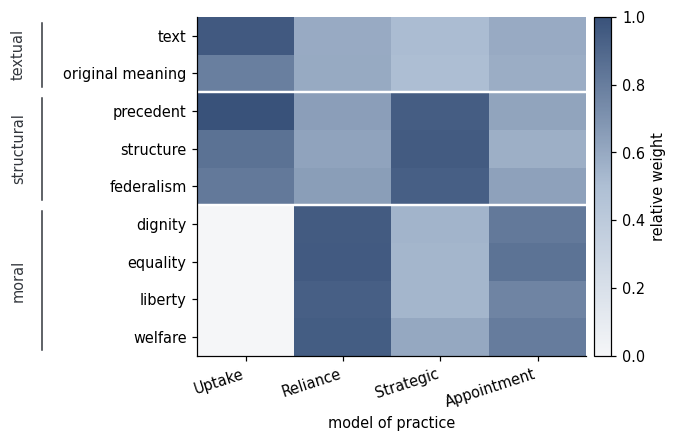

In [5]:
mechs=['uptake','reliance','strategic','appointment']; H=W4.loc[PN, mechs].values
fig,ax=plt.subplots(figsize=(6.0,4.0)); fig.subplots_adjust(left=0.34, right=0.97)
im=ax.imshow(H, aspect='auto', cmap=SOFTMAP, vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels([m.capitalize() for m in mechs], rotation=18, ha='right')
ax.set_yticks(range(9)); ax.set_yticklabels([PRETTY[p] for p in PN]); ax.set_xlabel('model of practice')
trans=ax.get_yaxis_transform()                              # x in axes-fraction, y in data coords
for nm,idx in BANDS:
    ax.text(-0.46, np.mean(idx), nm, va='center', ha='center', rotation=90, color=INK, transform=trans, clip_on=False)
    ax.plot([-0.40,-0.40],[idx[0]-.35,idx[-1]+.35], color=INK, lw=1, transform=trans, clip_on=False)
for b in (1.5,4.5): ax.axhline(b, color='white', lw=1.6)
cb=plt.colorbar(im, ax=ax, fraction=.045, pad=.02); cb.set_label('relative weight')
MANIFEST['F2']=savefig(fig,2,'practice_not_unitary')
SRCVALS['F2']={'reliance_appointment_sp':CD['reliance-appointment'], 'appointment_noise':M4.loc['appointment','R2'], 'uptake_dignity':W4.loc['dignity','uptake']}

## F3 -- The threshold is a modeling choice

The model calls a case 'determinate' when net force clears a threshold. Raising it
lowers the determinacy rate smoothly, for every mechanism -- there is no privileged
value, and 0.20 is merely a common default. (Berman himself decides by the *sign*
of net force and welcomes underdeterminacy, the threshold-to-zero limit.) The
conclusions don't hinge on the number; even at a high threshold most cases are still
decided.

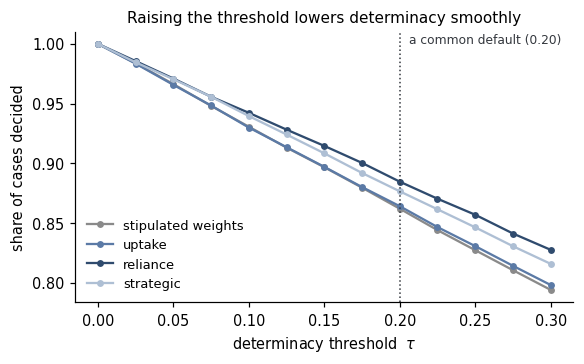

In [6]:
F3LBL={'stipulated':'stipulated weights','uptake':'uptake','reliance':'reliance','strategic':'strategic'}
fig,ax=plt.subplots(figsize=(5.4,3.4))
for m in ['stipulated','uptake','reliance','strategic']:
    sub=TAU[TAU.mechanism==m].sort_values('tau'); ax.plot(sub.tau, sub.determinacy, 'o-', color=MECHC[m], ms=3.5, lw=1.5, label=F3LBL[m])
ax.axvline(DEFAULT_TAU, color=INK, ls=':', lw=1)
ax.text(DEFAULT_TAU+.006, 0.955, 'a common default (0.20)', fontsize=8, color=INK,
        transform=ax.get_xaxis_transform())
ax.set(xlabel=r'determinacy threshold  $\tau$', ylabel='share of cases decided', title='Raising the threshold lowers determinacy smoothly')
ax.legend(fontsize=8.5, frameon=False, loc='lower left')
fig.tight_layout()
MANIFEST['F3']=savefig(fig,3,'threshold_choice')
SRCVALS['F3']={'D_at_0_stip':float(TAU[(TAU.mechanism=='stipulated')&(TAU.tau==0.0)].determinacy.iloc[0])}

## F4 -- What the threshold drives, and what it doesn't

A global sensitivity analysis (Sobol indices, verified against a standard
benchmark). The threshold owns most of the variance in *whether a case is decided*
(left). But that grip is specific: for the substantive requirements -- delivering
more law than a hierarchy, and weighing magnitude -- it is the **activation
correlation**, not the threshold, that dominates (right).

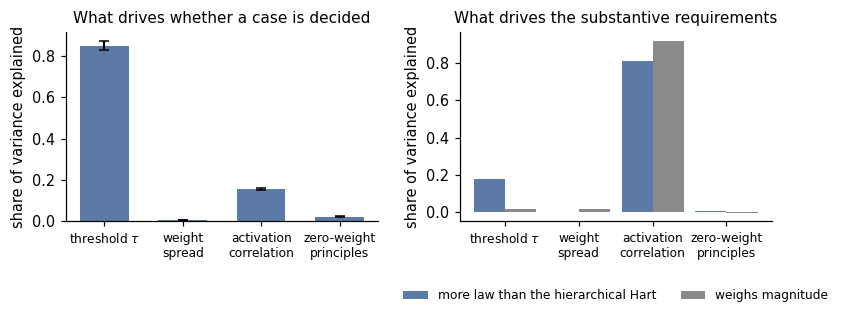

In [7]:
NICE={'tau':r'threshold $\tau$','w_spread':'weight\nspread','rho':'activation\ncorrelation','sparsity':'zero-weight\nprinciples'}
fig,ax=plt.subplots(1,2,figsize=(7.8,3.2))
inp=list(SOB.input); x=np.arange(len(inp)); err=[SOB.ST-SOB.ST_lo, SOB.ST_hi-SOB.ST]
ax[0].bar(x, SOB.ST, yerr=err, capsize=3, color=SLATE, width=.62)
ax[0].set_xticks(x); ax[0].set_xticklabels([NICE.get(i,i) for i in inp], fontsize=8)
ax[0].set(ylabel='share of variance explained', title='What drives whether a case is decided')
px=np.arange(len(PANEL.index))
ax[1].bar(px-0.21, PANEL['r4'], 0.42, color=SLATE, label='more law than the hierarchical Hart')
ax[1].bar(px+0.21, PANEL['r3'], 0.42, color=GREY, label='weighs magnitude')
ax[1].set_xticks(px); ax[1].set_xticklabels([NICE.get(i,i) for i in PANEL.index], fontsize=8)
ax[1].set(ylabel='share of variance explained', title='What drives the substantive requirements')
ax[1].legend(fontsize=8, frameon=False, loc='upper center', bbox_to_anchor=(0.5,-0.30), ncol=2)
fig.tight_layout()
MANIFEST['F4']=savefig(fig,4,'sensitivity')
SRCVALS['F4']={'tau_share_det':float(SOB[SOB.input=='tau'].ST.iloc[0]), 'rho_share_r4':float(PANEL.loc['rho','r4'])}

## F5 -- Only cardinal rules weigh how strongly a principle applies

The contrast Berman called striking. Probing each aggregation rule with a
magnitude-only change: the cardinal family (the weighted sum) responds; **every
counting rule is exactly zero** -- it never saw the magnitudes; the lexical foils
are essentially zero. Only the cardinal family is faithful to Berman.

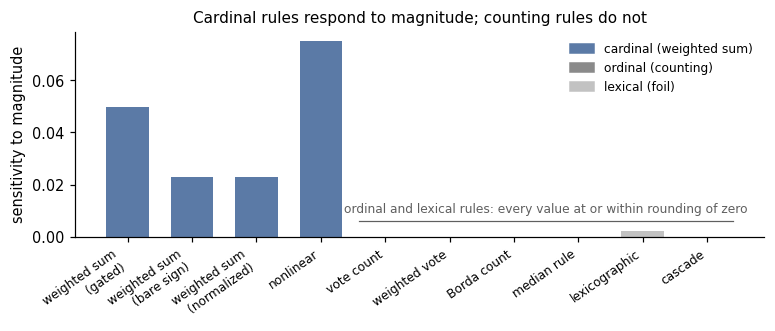

In [8]:
FC={'cardinal':SLATE,'ordinal':GREY,'lexical(FOIL)':GREYL}
LBL={'cardinal':'cardinal (weighted sum)','ordinal':'ordinal (counting)','lexical(FOIL)':'lexical (foil)'}
fig,ax=plt.subplots(figsize=(7.2,3.1)); x=np.arange(len(NLX))
ax.bar(x, NLX.nonlexicality, color=[FC[f] for f in NLX.family], width=.66)
F5LBL={'SAW (tau=0.2)':'weighted sum\n(gated)','SAW-sign':'weighted sum\n(bare sign)','SAW-L1':'weighted sum\n(normalized)',
       'Nonlinear':'nonlinear','vote-count':'vote count','weighted-vote':'weighted vote','Borda':'Borda count',
       'median-sign':'median rule','lexicographic':'lexicographic','cascade':'cascade'}
ax.set_xticks(x); ax.set_xticklabels([F5LBL.get(f,f) for f in NLX.function], rotation=35, ha='right', fontsize=8)
ax.set(ylabel='sensitivity to magnitude', title='Cardinal rules respond to magnitude; counting rules do not')
# The six right-hand bars sit ON the axis. Say so inside the plot area, or the
# legend promises swatches the reader cannot find.
_zero = NLX[NLX.family != 'cardinal']
_lo, _hi = x[len(NLX)-len(_zero)], x[-1]
ax.plot([_lo-0.4, _hi+0.4], [0.0062, 0.0062], color=GREYD, lw=0.8)
ax.text((_lo+_hi)/2, 0.0082, 'ordinal and lexical rules: every value at or within rounding of zero',
        ha='center', va='bottom', fontsize=8, color=GREYD)
ax.legend(handles=[mpatches.Patch(color=FC[k], label=LBL[k]) for k in ['cardinal','ordinal','lexical(FOIL)']], fontsize=8, frameon=False)
fig.tight_layout()
MANIFEST['F5']=savefig(fig,5,'cardinal_ordinal')
SRCVALS['F5']={'ordinal_max':float(NLX[NLX.family=='ordinal'].nonlexicality.max()), 'saw_sign':float(NLX[NLX.function=='SAW-sign'].nonlexicality.iloc[0])}

## Theorems table -- the results that hold by proof

Five results are proved, not simulated. These belong in the manuscript as a **table**,
not a figure, so we emit `theorems_table.tex` (a LaTeX `tabular`) rather than a PNG.

In [9]:
# Part VIII re-verifies Theorem 4 on a finer grid running down to tau = 0.
# That residual is reported by notebook 4, not recomputed here; it is carried
# so the table cannot drift from the manuscript on a re-run.
FINE_GRID_ERR = 0.0106

# The table separates what is PROVED from what the simulation CHECKS, because the
# five results are not proved in the same sense and the manuscript relies on the
# difference. T1 splits: the sum's half is universal, the rival's half is a
# conditional on the case. T2 is proved for reliance only. T4 carries a
# distributional assumption it cannot shed. T5's proof is a counterexample and
# supplies no rate; the 15% is Monte Carlo.
_af = S7['T1']['antecedent_frequency']
TROWS=[('The weighted sum returns one verdict on any case whatever. A rule certifying each direction separately returns two whenever at least two principles apply strongly each way, which is a condition on the case and not on the rule.',
        f"on the directly opposed battery, where that condition holds by construction, the rule contradicts itself on {S7['T1']['validation_contradiction_rate']:.0%} of cases and the sum on {S7['T1']['saw_contradiction_rate']:.0%}; the condition itself obtains on {_af['independent']:.0%} of independent draws, {_af['category_correlated']:.0%} of category-correlated ones, and {_af['fully_correlated']:.0%} under full correlation"),
       ('In the reliance mechanism, conferred weight is a function of pressure and activations and not of invocation propensity. Not proved for uptake, where weight is invocation frequency by construction.',
        f"two runs differing only in invocation frequency confer identical weights, to a difference of {S7['T2']['conferred_L1_diff']:.3f}, though their uptake shares differ"),
       ('The weighted sum responds to a change in magnitude alone; a rule reading only ranks cannot.',
        f"magnitude sensitivity {S7['T3']['saw_score']:.3f} for the sum against exactly {S7['T3']['lexical_thresholdless']:.3f} for a rank-only rule with no activation cutoff, and {S7['T3']['lexical_library']:.4f} for the implemented foil, which carries one"),
       ('For activations drawn independently and uniformly, net force has variance $\\tfrac{1}{3}\\sum_i w_i^2$ and the determinacy rate is $2(1-\\Phi(\\tau/\\sigma_F))$ under a normal approximation. Not proved for correlated activations.',
        f"simulation matches the formula to within {S7['T4']['max_abs_error_closed_form']:.3f} on the grid tested here, and {FINE_GRID_ERR:.4f} on the finer grid of Part VIII; both residuals measure the approximation rather than the implementation"),
       ('With equal weights the sum and a vote-count disagree on a set of positive measure. The proof is a counterexample and supplies no rate.',
        f"on nine principles the two disagree on {S7['T5']['disagreement_rate']:.1%} of cases, reproduced at 15.3% on the separate implementation of Part VII")]

# LaTeX escaping happens at write time only, so the console print below stays readable.
esc = lambda s: s.replace('%', r'\%')
with open(f'{PUB}/theorems_table.tex','w') as f:
    f.write('\\begin{tabular}{p{0.44\\textwidth} p{0.48\\textwidth}}\n\\toprule\n')
    f.write('\\textbf{What is proved} & \\textbf{What the simulation adds} \\\\\n\\midrule\n')
    for j,(stmt,stat) in enumerate(TROWS):
        if j: f.write('\\addlinespace\n')     # dense prose rows need the separation
        f.write(f'{esc(stmt)} & {esc(stat)} \\\\\n')
    f.write('\\bottomrule\n\\end{tabular}\n')

# Guard: an unescaped % here silently breaks the tabular in the compiled manuscript.
_tbl = open(f'{PUB}/theorems_table.tex').read()
import re as _re
assert not _re.search(r'(?<!\\)%', _tbl), 'unescaped % written into theorems_table.tex'
assert _tbl.count(r'\\') == 1 + len(TROWS), 'row terminators lost -- a % probably ate one'

for stmt,stat in TROWS: print('-', stmt[:70], '|', stat[:70])
SRCVALS['TBL']={'T2_L1':S7['T2']['conferred_L1_diff'], 'T5_disagree':S7['T5']['disagreement_rate'],
                'T1_antecedent_indep':_af['independent']}


- The weighted sum returns one verdict on any case whatever. A rule cert | on the directly opposed battery, where that condition holds by constru
- In the reliance mechanism, conferred weight is a function of pressure  | two runs differing only in invocation frequency confer identical weigh
- The weighted sum responds to a change in magnitude alone; a rule readi | magnitude sensitivity 0.023 for the sum against exactly 0.000 for a ra
- For activations drawn independently and uniformly, net force has varia | simulation matches the formula to within 0.006 on the grid tested here
- With equal weights the sum and a vote-count disagree on a set of posit | on nine principles the two disagree on 15% of cases, reproduced at 15.


## Manifest and captions

A machine-readable manifest and a paste-ready LaTeX caption file. The captions carry every number and every definition (the figures themselves stay clean).

In [10]:
# Kept in step with the live \caption{} text in the manuscript sections.
# F1's left panel is the OPPOSED battery at 30-seed means, not a mixed battery.
CAPTIONS={
 'F1':'The static weighted sum. Left: on six thousand opposed cases, the hardest conflict type, a Hartian validation rule contradicts itself on 100% of them, certifying both outcomes at once; the weighted sum never contradicts itself, deciding about 52% at tau = 0.2 and reporting the rest as unresolved. Thirty-seed means. The sum\'s coherence holds as an entailment; the rule\'s 100% is the rate on cases built to be directly opposed, and on unstructured draws it is 45.4%; the determinacy rate is measured throughout. See Section IV.D. Right: net legal force on three worked examples, the sign giving the verdict. TVA v. Hill returns +1.205 under Burger and -0.285 under Powell, opposite determinate verdicts on one statute, and Obergefell returns +0.295.',
 'F2':'Practice is not unitary. Each column is one mechanism\'s emergent weight structure across the nine principles; darker cells carry more weight. All four mechanisms clear the four requirements of Part III. Uptake concentrates on the textual and structural principles and drives the four moral principles to zero; reliance and appointment lift the moral principles highest; strategic lifts the structural principles highest. Reliance and appointment converge (rank correlation +0.93 between the mean weight vectors), so the four dynamics realize three distinct structures, not four. Appointment is the marginal mechanism on noise tolerance, clearing it on twenty-six of thirty seeds. The heavier moral tier under reliance and appointment is partly a category-size effect: the moral tier holds four principles to the structural tier\'s three and the textual tier\'s two, so under correlated activations it accrues broader aggregate force.',
 'F3':'The determinacy threshold is a choice the theory does not make. A case counts as determinate when the size of its net force exceeds the threshold tau. Raising tau lowers the share of cases decided smoothly and monotonically for every mechanism plotted, from 1.000 at tau = 0 to between 0.794 and 0.828 at tau = 0.30, with no kink, no plateau, and no privileged value anywhere on the curve; 0.20 is a common default and is marked for reference, where the stipulated engine decides 86.2% of cases. The curve has a closed form in tau, which the simulation matches to a maximum error of 0.0106. Berman\'s text permits an aggregative system to eschew thresholds altogether, so the faithful baseline is the bare sign of net force, the tau = 0 end of this figure, where determinacy is at its maximum. Curves are thirty-seed means for the stipulated engine of Part IV and for the uptake, reliance, and strategic mechanisms of Part VI; the appointment mechanism\'s weights come from a separate simulation this sweep does not rebuild. All four requirements of Part III hold across the whole range for each of the three emergent mechanisms plotted.',
 'F4':'What the threshold governs. A global sensitivity analysis apportions the variance in each output among four inputs varied together: the threshold, the weights\' dispersion, the correlation among activations, and the share of principles carrying no weight. Left: for whether a case is decided at all, the threshold dominates, taking a total-order variance share of 0.849 (95% confidence interval 0.827 to 0.871), against 0.156 for activation correlation, 0.023 for sparsity, and 0.008 for weight dispersion. Right: for the substantive requirements the ordering reverses. On the margin over the hierarchical Hart the threshold\'s first-order share is 0.176 against activation correlation\'s 0.810, and on the magnitude probe 0.020 against 0.919. The left panel reports total-order shares, which include each input\'s interactions with the others; the right panel reports first-order shares from a smaller run and should be read as a ranking rather than as precise shares. The threshold governs how much law comes out determinate. It does not govern whether the model\'s substantive properties hold.',
 'F5':'Only cardinal aggregation reads how strongly a principle applies. Under a magnitude-only perturbation, which holds every sign and every within-case rank fixed and changes only the strengths, the four cardinal rules change their verdicts on 2.3% to 7.5% of cases; the weighted sum sits at 4.96% with its determinacy gate at tau = 0.2 and at 2.3% on the bare sign of net force. Every ordinal rule changes its verdict on exactly none of them (0.000, by construction, having never read a magnitude), and the lexical foils on effectively none (lexicographic 0.24%, cascade 0.000). The measurement separates the cardinal family from the other six rules by roughly a factor of ten at its narrowest. It does not separate the ordinal rival from the lexical foil, which sit together at or within rounding of zero; that division is conceptual, not one this instrument reports.',
 'theorems_table':'The five results, and the scope each is proved under. Two hold on any activation distribution whatever. One divides: the weighted sum never contradicts itself on any case, while a validation rule contradicts itself whenever at least two principles apply strongly each way, which is a condition on the case. One holds for the reliance mechanism only, since under uptake a principle\'s weight simply is its invocation frequency. One holds under independent activations and does not carry over to correlated ones. The right-hand column reports what the simulation adds rather than what establishes the result.'}

with open(f'{PUB}/captions.tex','w') as f:
    for k in ['F1','F2','F3','F4','F5']:
        f.write('%% ' + k + '\n\\caption{' + CAPTIONS[k].replace('%', r'\%') + '}\n\n')
with open(f'{PUB}/FIGURE_MANIFEST.json','w') as f:
    json.dump({k:{'file':MANIFEST[k],'caption':CAPTIONS[k]} for k in ['F1','F2','F3','F4','F5']}
              | {'theorems_table':{'file':'theorems_table.tex','caption':CAPTIONS['theorems_table']}}, f, indent=2)
print('wrote captions.tex and FIGURE_MANIFEST.json')
for k in CAPTIONS: print(' ', k, '->', CAPTIONS[k][:70].replace('\n',' '), '...')


wrote captions.tex and FIGURE_MANIFEST.json
  F1 -> The static weighted sum. Left: on six thousand opposed cases, the hard ...
  F2 -> Practice is not unitary. Each column is one mechanism's emergent weigh ...
  F3 -> The determinacy threshold is a choice the theory does not make. A case ...
  F4 -> What the threshold governs. A global sensitivity analysis apportions t ...
  F5 -> Only cardinal aggregation reads how strongly a principle applies. Unde ...
  theorems_table -> The five results, and the scope each is proved under. Two hold on any  ...


## Self-check

Every figure (PDF + PNG) and the theorems table were written, the manifest and captions exist, and the key numbers match a fresh re-read of their source files.

In [11]:
ok=True
def check(name, cond):
    global ok; ok=ok and bool(cond); print(('PASS' if cond else 'FAIL')+' - '+name)
# (A) files written
for n in range(1,6):
    pdf=f'{PUB}/'+MANIFEST[f'F{n}']; png=pdf[:-4]+'.png'
    check(f'F{n} PDF+PNG written, non-empty', os.path.getsize(pdf)>0 and os.path.getsize(png)>0)
check('theorems_table.tex written, non-empty', os.path.getsize(f'{PUB}/theorems_table.tex')>0)
check('FIGURE_MANIFEST.json + captions.tex written', os.path.exists(f'{PUB}/FIGURE_MANIFEST.json') and os.path.exists(f'{PUB}/captions.tex'))
# (B) numbers match a fresh re-read of source
r0=L('data/notebook0/notebook0_summary.json'); r9w=pd.read_csv('data/notebook9/exp_fourway_weights.csv',index_col=0)
r9m=pd.read_csv('data/notebook9/exp_fourway_metrics.csv',index_col=0); r9c=pd.read_csv('data/notebook9/exp_fourway_corr.csv')
r6=pd.read_csv('data/notebook6/sobol_determinacy.csv'); r5=pd.read_csv('data/notebook5/nb5_nonlexicality.csv'); r7=L('data/notebook7_results.json')
tol=1e-6
check('F1 Hart contradiction matches source', abs(SRCVALS['F1']['hart_contradiction']-r0['exp3b']['hart']['contradiction'])<tol)
check('F1 Berman indeterminacy matches source', abs(SRCVALS['F1']['berman_indeterminate']-r0['exp3b']['berman']['indeterminate'])<tol)
check('F2 reliance~appointment correlation matches source', abs(SRCVALS['F2']['reliance_appointment_sp']-float(r9c[r9c.pair=='reliance-appointment'].spearman.iloc[0]))<tol)
check('F2 appointment noise-tolerance matches source (the lone marginal value)', abs(SRCVALS['F2']['appointment_noise']-float(r9m.loc['appointment','R2']))<tol)
check('F2 uptake zeros the moral tier (dignity weight = 0)', abs(float(r9w.loc['dignity','uptake']))<tol)
check('F4 threshold share of determinacy variance matches source', abs(SRCVALS['F4']['tau_share_det']-float(r6[r6.input=='tau'].ST.iloc[0]))<tol)
check('F5 ordinal magnitude-sensitivity exactly 0', abs(SRCVALS['F5']['ordinal_max'])<tol)
check('Theorems table: conferred weight identical, difference exactly 0', abs(SRCVALS['TBL']['T2_L1']-r7['T2']['conferred_L1_diff'])<tol)
# substantive honesty guards
check('central finding intact: appointment converges with reliance (>0.7)', SRCVALS['F2']['reliance_appointment_sp']>0.7)
check('honesty intact: exactly one requirement cell below 1.0', int((r9m[['R1','R2','R3','R4']].values<1.0).sum())==1)
print('\n'+('ALL CHECKS PASSED' if ok else 'SOME CHECKS FAILED')); assert ok, 'self-check failed'

PASS - F1 PDF+PNG written, non-empty
PASS - F2 PDF+PNG written, non-empty
PASS - F3 PDF+PNG written, non-empty
PASS - F4 PDF+PNG written, non-empty
PASS - F5 PDF+PNG written, non-empty
PASS - theorems_table.tex written, non-empty
PASS - FIGURE_MANIFEST.json + captions.tex written
PASS - F1 Hart contradiction matches source
PASS - F1 Berman indeterminacy matches source
PASS - F2 reliance~appointment correlation matches source
PASS - F2 appointment noise-tolerance matches source (the lone marginal value)
PASS - F2 uptake zeros the moral tier (dignity weight = 0)
PASS - F4 threshold share of determinacy variance matches source
PASS - F5 ordinal magnitude-sensitivity exactly 0
PASS - Theorems table: conferred weight identical, difference exactly 0
PASS - central finding intact: appointment converges with reliance (>0.7)
PASS - honesty intact: exactly one requirement cell below 1.0

ALL CHECKS PASSED


## What this notebook produces

Five publication figures in `figures/pub/` (vector PDF for LaTeX + 600-dpi PNG), a
`theorems_table.tex`, a `FIGURE_MANIFEST.json`, and a paste-ready `captions.tex`.
Each figure is rendered purely from the saved outputs of Notebooks 0-9 and
self-checks against its source, so the figures and the data can never drift. They
use one muted palette (slate blue + grayscale) and plain-language labels, with every
number in the caption -- built to drop into a law review. Together they carry the
paper's honest arc: a faithful static core, the threshold as a modeling choice,
**practice is not unitary** (four mechanisms, three structures, all meeting what
Berman requires), the cardinal-vs-ordinal contrast, and the results that hold by
proof.